In [25]:
# ¿Cómo podemos predecir el consumo de combustible (MPG) de un automóvil a partir de sus características técnicas?

import pandas as pd

dataset = pd.read_csv("../data/auto_mpg.csv")
dataset.head()



,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


In [26]:
# --

# Tamaño del dataset
dataset.shape

# --

# Búsqueda de valores nulos

dataset.isna().sum()

# --




MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [27]:
 
# La categoría se conserva hasta que OneHotEncoder la transforma sin imponer un orden entre países.

dataset["Origin"] = dataset["Origin"].astype("category")
dataset.dtypes["Origin"]

# --

CategoricalDtype(categories=[1, 2, 3], ordered=False, categories_dtype=int64)

In [28]:

# Se debe conservar la categoría de origen para codificarla después de separar entrenamiento y prueba.

dataset.head()

# ---

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,1


In [29]:

# Se deben separar vehículos para entrenamiento y prueba con una partición reproducible.
import sys
!{sys.executable} -m pip install scikit-learn

from sklearn.model_selection import train_test_split

train_dataset, test_dataset = train_test_split(
    dataset,
    train_size=0.8,
    random_state=0,
)



# ---


/workspaces/std-max-steven-hurtado-ramos/.venv312/bin/python: No module named pip


/workspaces/std-max-steven-hurtado-ramos/.venv312/lib/python3.12/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/workspaces/std-max-steven-hurtado-ramos/.venv312/lib/python3.12/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/workspaces/std-max-steven-hurtado-ramos/.venv312/lib/python3.12/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/workspaces/std-max-steven-hurtado-ramos/.venv312/lib/python3.12/site-packages/seaborn/_oldcor

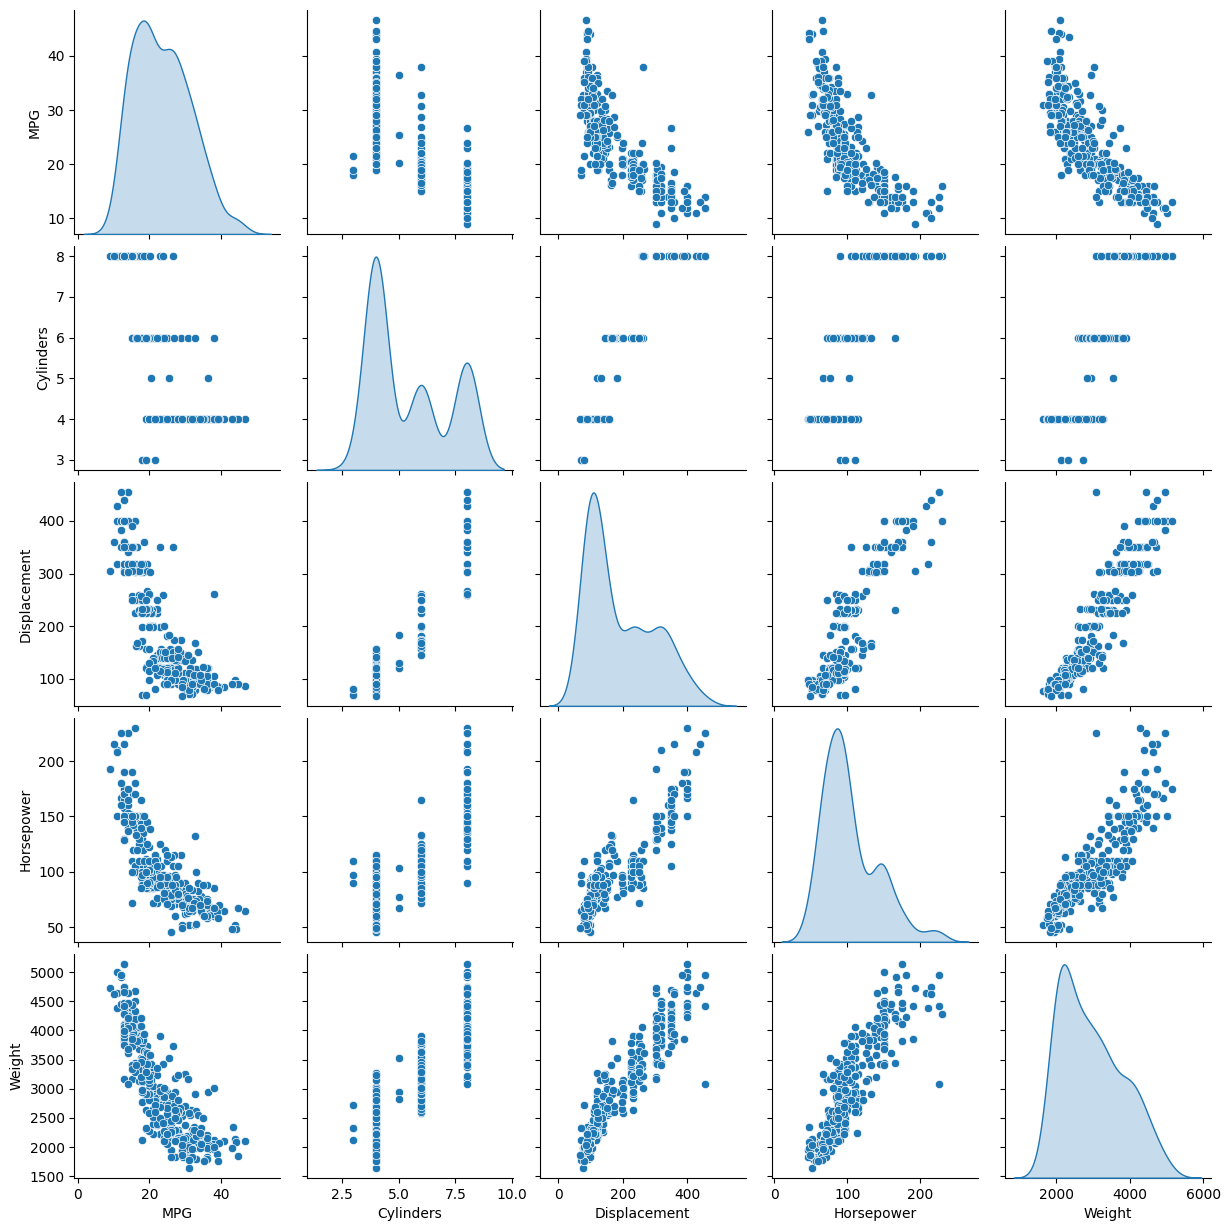

In [30]:

# Horsepower debe aparecer porque se usa directamente en la primera especificación predictiva.

import seaborn as sns

sns.pairplot(
    train_dataset[["MPG", "Cylinders", "Displacement", "Horsepower", "Weight"]],
    diag_kind="kde",
)

# ---


In [31]:
# Variables predictoras y objetivo; el conjunto de prueba se mantiene aparte.

target = "MPG"
feature_columns = [column for column in dataset.columns if column != target]

X_train = train_dataset[feature_columns]
X_test = test_dataset[feature_columns]
y_train = train_dataset[target]
y_test = test_dataset[target]

print(f"Entrenamiento: {X_train.shape[0]} vehículos")
print(f"Prueba: {X_test.shape[0]} vehículos")


Entrenamiento: 318 vehículos
Prueba: 80 vehículos


In [32]:
# Imputar los valores faltantes y escalar variables numéricas dentro del pipeline.

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["category", "object"]
).columns.tolist()

numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

features_preprocessor = ColumnTransformer(
    transformers=[("horsepower", numeric_preprocessor, ["Horsepower"])]
)

flexible_features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ]
)


In [33]:
# Comparar una regresión simple con una regresión lineal que usa todas las características.

from sklearn.base import clone
from sklearn.linear_model import LinearRegression

baseline_model = Pipeline(
    steps=[
        ("preprocessor", clone(features_preprocessor)),
        ("regressor", LinearRegression()),
    ]
)

linear_flexible_model = Pipeline(
    steps=[
        ("preprocessor", clone(flexible_features_preprocessor)),
        ("regressor", LinearRegression()),
    ]
)

baseline_model.fit(X_train, y_train)
linear_flexible_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Cylinders', 'Displacement',
                                                   'Horsepower', 'Weight',
                                                   'Acceleration',
                                                   'Model Year']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Origin'])])),
                ('regressor', LinearRegression())])

In [34]:
# Una red neuronal ofrece una relación no lineal más flexible entre características y MPG.

from sklearn.neural_network import MLPRegressor

mlp = Pipeline(
    steps=[
        ("preprocessor", clone(flexible_features_preprocessor)),
        (
            "regressor",
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=0.001,
                max_iter=1500,
                early_stopping=True,
                random_state=0,
            ),
        ),
    ]
)

mlp.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Cylinders', 'Displacement',
                                                   'Horsepower', 'Weight',
                                                   'Acceleration',
                                                   'Model Year']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Origin'])])),
                ('regressor',
                 MLPRegressor(alpha=0.001, early_stopping=True,
                              hidden_layer_sizes=(64, 32), max_iter=1500,
                              random_state=0))])

In [35]:
# Evaluar todos los modelos sobre los mismos vehículos de prueba.

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Regresión simple (Horsepower)": baseline_model,
    "Regresión lineal flexible": linear_flexible_model,
    "Red neuronal (MLP)": mlp,
}

comparison = []
for model_name, model in models.items():
    predictions = model.predict(X_test)
    comparison.append(
        {
            "model": model_name,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions),
        }
    )

model_comparison = pd.DataFrame(comparison).sort_values("RMSE").reset_index(drop=True)
model_comparison


,model,MAE,RMSE,R2
0,Red neuronal (MLP),2.329429,3.207647,0.837860
1,Regresión lineal flexible,2.697201,3.309608,0.827388
2,Regresión simple (Horsepower),4.489352,5.564654,0.512029


In [36]:
# Guardar los preprocesadores y modelos entrenados para reutilizarlos sin reentrenar.

from pathlib import Path
import joblib

submission_directory = Path("../submission")
submission_directory.mkdir(parents=True, exist_ok=True)

joblib.dump(
    baseline_model.named_steps["preprocessor"],
    submission_directory / "features_preprocessor.pkl",
)
joblib.dump(
    linear_flexible_model.named_steps["preprocessor"],
    submission_directory / "flexible_features_preprocessor.pkl",
)
joblib.dump(
    linear_flexible_model,
    submission_directory / "linear_flexible_model.pkl",
)
joblib.dump(mlp, submission_directory / "mlp.pkl")
model_comparison.to_csv(
    submission_directory / "model_comparison.csv",
    index=False,
)

print(f"Entregables guardados en: {submission_directory.resolve()}")


Entregables guardados en: /workspaces/std-max-steven-hurtado-ramos/P200_regresion_basica/submission


In [37]:

# Cálculo de algunas estadísticas generales

train_dataset.describe().transpose()

# ---

,count,mean,std,min,25%,50%,75%,max
MPG,318.0,23.574843,7.776499,9.0,17.50,23.0,29.00,46.6
Cylinders,318.0,5.452830,1.706170,3.0,4.00,4.0,8.00,8.0
Displacement,318.0,191.800314,102.795417,68.0,101.75,148.5,262.00,455.0
Horsepower,313.0,103.702875,37.723750,46.0,75.00,93.0,125.00,230.0
Weight,318.0,2963.393082,845.227078,1649.0,2216.25,2822.5,3561.25,5140.0
Acceleration,318.0,15.644654,2.701224,8.0,14.00,15.5,17.15,24.8
Model Year,318.0,76.147799,3.652083,70.0,73.00,76.0,79.00,82.0


In [38]:
# Particionamiento de los datos en features y labels

train_features = train_dataset.copy()
train_labels = train_features.pop("MPG")

test_features = test_dataset.copy()
test_labels = test_features.pop("MPG")

# ---

In [39]:
## ---

# Se debe revisar el efecto del escalamiento solo sobre las variables numéricas.

numeric_columns = train_dataset.select_dtypes(include="number").columns

train_dataset[numeric_columns].describe().transpose()[["mean", "std"]]

# ---

,mean,std
MPG,23.574843,7.776499
Cylinders,5.452830,1.706170
Displacement,191.800314,102.795417
Horsepower,103.702875,37.723750
Weight,2963.393082,845.227078
Acceleration,15.644654,2.701224
Model Year,76.147799,3.652083


In [40]:
# Se debe observar cómo StandardScaler centra y escala las variables numéricas.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

pd.DataFrame(
    data=scaler.fit_transform(train_dataset[numeric_columns]),
    columns=numeric_columns,
).describe().transpose()[["mean", "std"]]

# --



,mean,std
MPG,-2.932665e-16,1.001576
Cylinders,5.167076e-17,1.001576
Displacement,-5.586028e-18,1.001576
Horsepower,7.661603e-17,1.001601
Weight,8.658343e-17,1.001576
Acceleration,-8.099740e-17,1.001576
Model Year,4.650368e-16,1.001576


primer modelo


In [41]:
# Regresión lineal con una sola variable (Horsepower)

horsepower_scaler = StandardScaler()

train_horsepower = train_features[["Horsepower"]]
test_horsepower = test_features[["Horsepower"]]

horsepower_scaler.fit(train_horsepower)

standarized_train_horsepower = horsepower_scaler.transform(train_horsepower)
standarized_test_horsepower = horsepower_scaler.transform(test_horsepower)


# ---


In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

horsepower_model = Pipeline(
    steps=[
        ("preprocessor", features_preprocessor),
        ("regressor", LinearRegression()),
    ]
)

# Entrenamos directamente con los datos originales (sin escalar previamente)
horsepower_model.fit(train_features, train_labels)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('horsepower',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Horsepower'])])),
                ('regressor', LinearRegression())])

In [43]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Imputar los valores NaN con la mediana
imputer = SimpleImputer(strategy="median")
imputed_train_horsepower = imputer.fit_transform(train_features[["Horsepower"]])

# 2. Estandarizar los datos ya imputados
scaler = StandardScaler()
standarized_train_horsepower = scaler.fit_transform(imputed_train_horsepower)

# 3. Entrenar el modelo
horsepower_model = LinearRegression()
horsepower_model.fit(standarized_train_horsepower, train_labels)


LinearRegression()

In [44]:

# Modelo de regresión lineal

from sklearn.linear_model import LinearRegression

horsepower_model = LinearRegression()
horsepower_model.fit(standarized_train_horsepower, train_labels)



# ---


LinearRegression()

In [45]:
# Coeficientes
horsepower_model.coef_

# --

array([-6.11416519])

In [46]:
# Modelo de regresión lineal

from sklearn.linear_model import LinearRegression

horsepower_model = LinearRegression()
horsepower_model.fit(standarized_train_horsepower, train_labels)

LinearRegression()

In [47]:
# Intercepto
horsepower_model.intercept_


23.5748427672956

In [48]:
# Coeficientes
horsepower_model.coef_

array([-6.11416519])

In [49]:

# Predicción. Preparación de las variables independientes

import numpy as np

x = pd.DataFrame({"Horsepower": np.linspace(0, 250, 251)})
x.head()

# --

,Horsepower
0,0.0
1,1.0
2,2.0
3,3.0
4,4.0


In [50]:
# Predicción

scaled_x = horsepower_scaler.transform(x)
y = horsepower_model.predict(scaled_x)
y[:5]


# ---

array([40.40964354, 40.24730666, 40.08496979, 39.92263291, 39.76029604])

In [51]:
# ---

import matplotlib.pyplot as plt


def plot_horsepower(x, y):
    plt.scatter(train_features["Horsepower"], train_labels, label="Data")
    plt.plot(x, y, color="k", label="Predictions")
    plt.xlabel("Horsepower")
    plt.ylabel("MPG")
    plt.legend()

# --


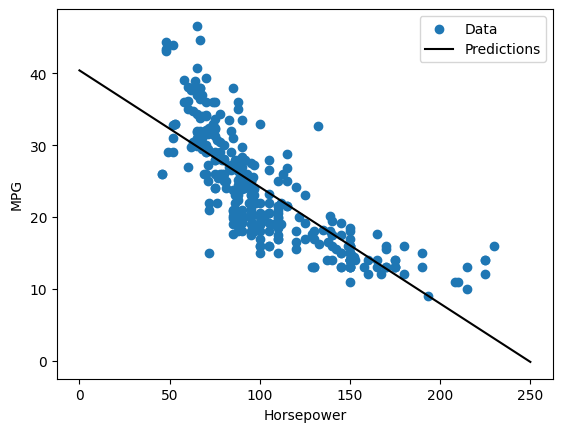

In [52]:

plot_horsepower(x, y)


# --

In [53]:
#import matplotlib.pyplot as plt


def plot_horsepower(x, y):
    plt.scatter(train_features["Horsepower"], train_labels, label="Data")
    plt.plot(x, y, color="k", label="Predictions")
    plt.xlabel("Horsepower")
    plt.ylabel("MPG")
    plt.legend()

# --

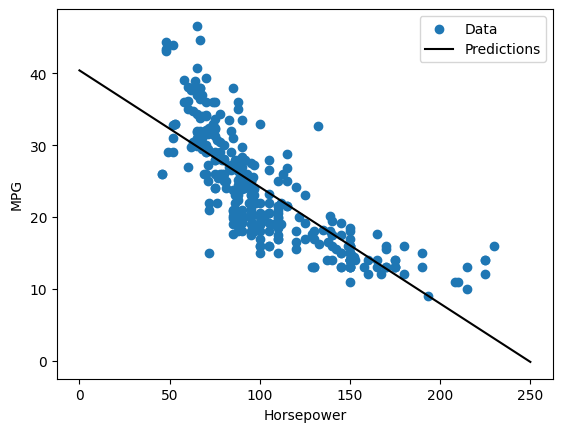

In [54]:
plot_horsepower(x, y)


# --


In [55]:
from sklearn.metrics import mean_squared_error

# 1. Transformar los datos de prueba con el imputer y scaler ya entrenados
imputed_test_horsepower = imputer.transform(test_features[["Horsepower"]])
standarized_test_horsepower = scaler.transform(imputed_test_horsepower)

# 2. Predecir y calcular el error
test_results = {}
y_pred = horsepower_model.predict(standarized_test_horsepower)

test_results["horsepower_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=y_pred,
)

test_results


{'horsepower_model': 30.965374890506688}

In [56]:

# Evaluación

from sklearn.metrics import mean_squared_error

test_results = {}

y_pred = horsepower_model.predict(standarized_test_horsepower)

test_results["horsepower_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=y_pred,
)

test_results

{'horsepower_model': 30.965374890506688}

In [57]:

# --
# Se deben ajustar el escalamiento y la codificación solo con los vehículos de entrenamiento.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = train_features.select_dtypes(include="number").columns.tolist()
categorical_features = ["Origin"]

features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "origin",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ],
)



# ---


In [58]:
standarized_train_features = flexible_features_preprocessor.fit_transform(train_features)
standarized_test_features = flexible_features_preprocessor.transform(test_features)

linear_model = LinearRegression()
linear_model.fit(standarized_train_features, train_labels)

# Ahora sí podrás ver el intercepto sin error
linear_model.intercept_


24.380482632520216

In [59]:
# Intercepto
linear_model.intercept_

# ---

24.380482632520216

In [60]:

# Coeficientes
linear_model.coef_

# ---

array([-0.68202582,  2.58711517, -0.78274473, -5.62721043,  0.5142342 ,
        2.7905719 , -1.93166567,  0.72527708,  1.20638859])

In [61]:

def plot_predictions(y_true, y_pred):

    plt.axes(aspect="equal") 
    plt.scatter(y_true, y_pred)
    plt.xlabel("True Values [MPG]")
    plt.ylabel("Predictions [MPG]")
    lims = [0, 50]
    plt.xlim(lims)
    plt.ylim(lims)
    _ = plt.plot(lims, lims)

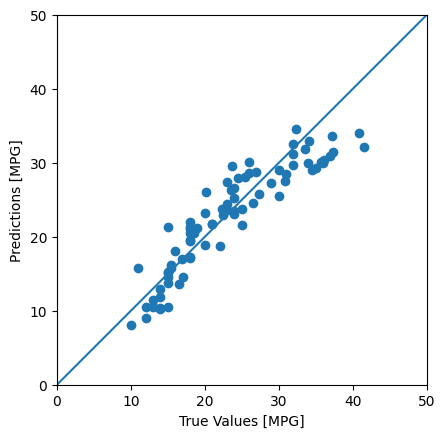

In [62]:
# --

test_predictions = linear_model.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)


# --

In [63]:
# --

test_results["linear_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=test_predictions,
)

test_results

# ---

{'horsepower_model': 30.965374890506688, 'linear_model': 10.95350265691782}

In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = train_features.select_dtypes(include="number").columns.tolist()
categorical_features = train_features.select_dtypes(include=["category", "object"]).columns.tolist()

numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ]
)


In [65]:

# Se agregan un término cuadrático y una interacción Weight × Horsepower para flexibilizar el modelo lineal.

train_features_flexible = train_features.copy()
test_features_flexible = test_features.copy()

for features in [train_features_flexible, test_features_flexible]:
    features["Horsepower_squared"] = features["Horsepower"] ** 2
    features["Weight_x_Horsepower"] = features["Weight"] * features["Horsepower"]

train_features_flexible[["Horsepower", "Horsepower_squared", "Weight", "Weight_x_Horsepower"]].head()

,Horsepower,Horsepower_squared,Weight,Weight_x_Horsepower
64,150.0,22500.0,4135.0,620250.0
55,60.0,3600.0,1834.0,110040.0
317,78.0,6084.0,2188.0,170664.0
102,46.0,2116.0,1950.0,89700.0
358,74.0,5476.0,2635.0,194990.0


In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

flexible_numeric_features = train_features_flexible.select_dtypes(
    include="number"
).columns.tolist()

# 1. Pipeline numérico: primero imputa con la mediana, luego escala
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# 2. Pipeline categórico: imputa con la moda y aplica OneHotEncoder
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

# 3. ColumnTransformer actualizado
flexible_features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, flexible_numeric_features),
        ("origin", categorical_transformer, categorical_features),
    ],
)

flexible_train_features = flexible_features_preprocessor.fit_transform(
    train_features_flexible
)
flexible_test_features = flexible_features_preprocessor.transform(
    test_features_flexible
)

linear_flexible_model = LinearRegression()
linear_flexible_model.fit(flexible_train_features, train_labels)

flexible_predictions = linear_flexible_model.predict(flexible_test_features)
test_results["linear_flexible_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=flexible_predictions,
)

test_results


{'horsepower_model': 30.965374890506688,
 'linear_model': 10.95350265691782,
 'linear_flexible_model': 8.508967674832055}

#flexible

In [67]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

flexible_numeric_features = (
    train_features_flexible
    .select_dtypes(include="number")
    .columns
    .tolist()
)

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )),
])

flexible_features_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, flexible_numeric_features),
        ("origin", categorical_preprocessor, categorical_features),
    ],
)

flexible_train_features = flexible_features_preprocessor.fit_transform(
    train_features_flexible
)
flexible_test_features = flexible_features_preprocessor.transform(
    test_features_flexible
)

linear_flexible_model = LinearRegression()
linear_flexible_model.fit(flexible_train_features, train_labels)

flexible_predictions = linear_flexible_model.predict(flexible_test_features)

test_results["linear_flexible_model"] = mean_squared_error(
    y_true=test_labels,
    y_pred=flexible_predictions,
)

test_results

{'horsepower_model': 30.965374890506688,
 'linear_model': 10.95350265691782,
 'linear_flexible_model': 8.508967674832055}

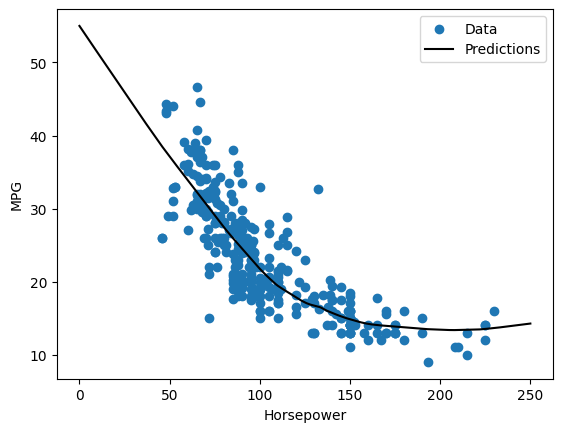

In [68]:

# Red neuronal con una sola entrada (Horsepower)

from sklearn.neural_network import MLPRegressor

mlp_horsepower = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)
mlp_horsepower.fit(standarized_train_horsepower, train_labels)

y = mlp_horsepower.predict(scaled_x)
plot_horsepower(x, y)


# --


In [69]:
# --

y_pred = mlp_horsepower.predict(standarized_test_horsepower)

test_results["mlp_horsepower"] = mean_squared_error(
    y_true=test_labels,
    y_pred=y_pred,
)

test_results

# --

{'horsepower_model': 30.965374890506688,
 'linear_model': 10.95350265691782,
 'linear_flexible_model': 8.508967674832055,
 'mlp_horsepower': 27.478644577375228}

In [70]:

# Red neuronal con todas las variables

mlp = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)


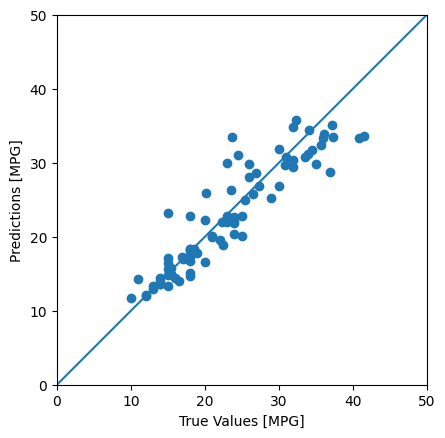

In [71]:

mlp.fit(standarized_train_features, train_labels)

test_predictions = mlp.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)


In [72]:

# --

# Red neuronal con todas las variables

mlp = MLPRegressor(
    max_iter=10000,
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    validation_fraction=0.2,
    early_stopping=True,
    random_state=0,
)


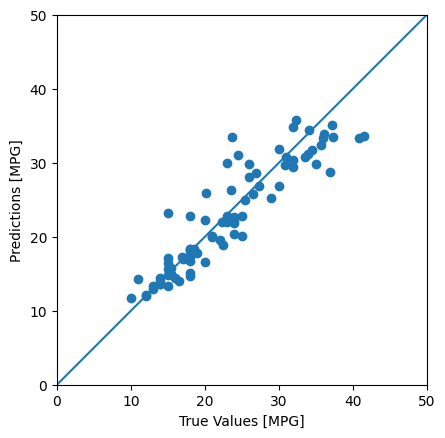

In [73]:
mlp.fit(standarized_train_features, train_labels)

test_predictions = mlp.predict(standarized_test_features)

plot_predictions(
    y_true=test_labels,
    y_pred=test_predictions,
)


In [74]:

test_results["mlp"] = mean_squared_error(
    y_true=test_labels,
    y_pred=test_predictions,
)


In [75]:

# Desempeño de los modelos

pd.DataFrame(test_results, index=["Mean squared error [MPG]"]).T.sort_values(
    by="Mean squared error [MPG]", ascending=False
)


,Mean squared error [MPG]
horsepower_model,30.965375
mlp_horsepower,27.478645
linear_model,10.953503
mlp,10.300175
linear_flexible_model,8.508968


In [76]:

# --


# Se almacenan los modelos, preprocesadores y la comparación de desempeño ajustados con entrenamiento.

import os
import pickle


with open("../submission/mlp.pkl", "wb") as file:
    pickle.dump(mlp, file)

with open("../submission/features_preprocessor.pkl", "wb") as file:
    pickle.dump(features_preprocessor, file)

with open("../submission/linear_flexible_model.pkl", "wb") as file:
    pickle.dump(linear_flexible_model, file)

with open("../submission/flexible_features_preprocessor.pkl", "wb") as file:
    pickle.dump(flexible_features_preprocessor, file)

pd.DataFrame(
    {
        "model": list(test_results),
        "test_mse": list(test_results.values()),
    }
).to_csv("../submission/model_comparison.csv", index=False)



In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

new_features_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                )),
            ]),
            categorical_features,
        ),
    ]
)

In [ ]:
# La predicción reutiliza el mismo tratamiento categórico aplicado durante el ajuste.

import pandas as pd

dataset = pd.read_csv("../data/auto_mpg.csv")
dataset = dataset.dropna()
dataset["Origin"] = dataset["Origin"].astype("category")
y_true = dataset.pop("MPG")

with open("../submission/mlp.pkl", "rb") as file:
    new_mlp = pickle.load(file)

with open("../submission/features_preprocessor.pkl", "rb") as file:
    new_features_preprocessor = pickle.load(file)

standarized_dataset = new_features_preprocessor.transform(dataset)
y_pred = new_mlp.predict(standarized_dataset)

resultado = mean_squared_error(
    y_true=y_true,
    y_pred=y_pred,
)

resultado

/tmp/ipykernel_49056/2744361524.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  dataset["Origin"] = dataset["Origin"].astype("category")


8.187378856571367

In [ ]:
# ¿Cómo podemos clasificar imágenes de dígitos escritos a mano y revisar la incertidumbre de cada predicción?

import json
import pickle

import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split


# ---

In [ ]:

# Se cargan imágenes etiquetadas de dígitos para construir un clasificador.

digits = datasets.load_digits()

# ---



In [ ]:

# ¿Cuántas imágenes y píxeles están disponibles para entrenar el clasificador?

digits.images.shape  # type: ignore 

# ---

(1797, 8, 8)

In [ ]:

# Una imagen es una matriz de intensidades numéricas.

digits.images[0, :, :]

# ---

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

In [ ]:

# ¿Qué dígitos debe distinguir el modelo?

set(digits.target)

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

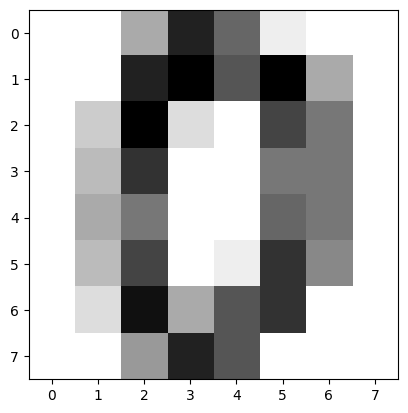

In [ ]:

# Se visualiza cómo se ve una matriz de píxeles para una persona.

plt.figure()
plt.imshow(digits.images[0], cmap=plt.cm.binary)
plt.grid(False)
plt.show()


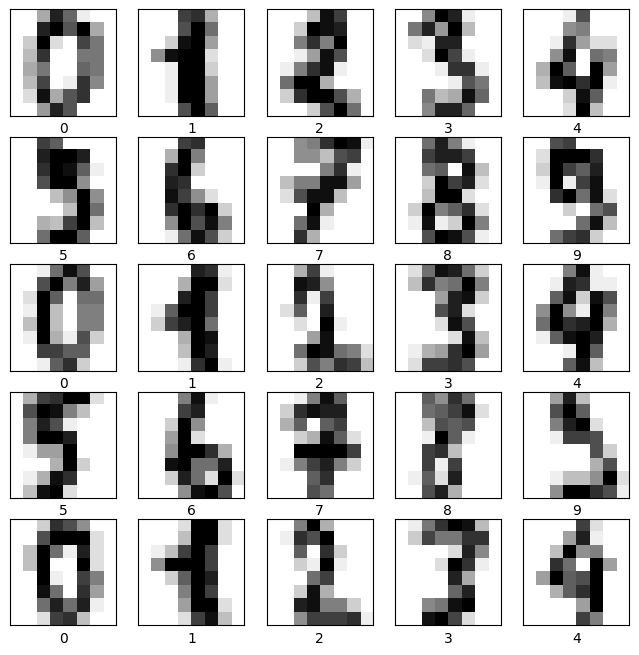

In [ ]:
# ---

plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(digits.images[i], cmap=plt.cm.binary)
    plt.xlabel(digits.target[i])
plt.show()

In [ ]:

# Cada imagen se representa como un vector de intensidades; así X almacena un ejemplo por fila y un píxel por columna.
#
# X
# ├── filas: imágenes (ejemplos)
# └── columnas: intensidades de píxel (features)

n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
data.shape


(1797, 64)

In [ ]:

# Se reservan imágenes de cada dígito para evaluar predicciones sobre datos no vistos.

X_train, X_test, y_train, y_test = train_test_split(
    data,
    digits.target,
    test_size=0.5,
    random_state=0,
    stratify=digits.target,
)


In [ ]:

# Se ajusta un clasificador que asigna una probabilidad a cada dígito posible.

estimator = LogisticRegression(max_iter=1000)

estimator.fit(
    X_train,
    y_train,
)

# ¿La precisión de entrenamiento es consistente con la de prueba?
accuracy_score(y_true=y_train, y_pred=estimator.predict(X_train))


1.0

In [ ]:

# Se calculan las probabilidades por clase y la precisión sobre las imágenes reservadas.

predictions = estimator.predict(X_test)
predicted_proba = estimator.predict_proba(X_test)

accuracy_score(y_true=y_test, y_pred=predictions)


0.9577308120133482

Confusion matrix:
[[88  0  0  0  1  0  0  0  0  0]
 [ 0 88  0  0  1  0  0  0  1  1]
 [ 0  1 86  1  0  0  0  0  0  0]
 [ 0  0  0 88  0  1  0  0  1  2]
 [ 0  2  0  0 88  0  0  0  1  0]
 [ 0  0  1  2  0 84  1  2  1  0]
 [ 0  2  0  0  1  1 86  0  1  0]
 [ 0  0  0  0  1  0  0 86  0  2]
 [ 0  4  3  0  0  0  0  0 79  1]
 [ 0  0  0  0  0  1  0  0  1 88]]


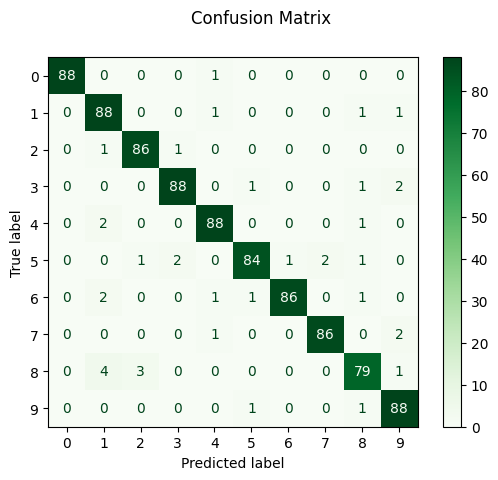

In [ ]:

# ¿Qué dígitos se confunden y qué revela eso sobre los errores del clasificador?

disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    cmap="Greens",
)
disp.figure_.suptitle("Confusion Matrix")
print(f"Confusion matrix:\n{disp.confusion_matrix}")


In [ ]:

# Se contrasta la etiqueta predicha, su probabilidad y la imagen real en casos concretos.


def plot_image(i, predicted_label, true_label, predicted_proba, img):

    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    #
    plt.imshow(img, cmap=plt.cm.binary)

    if predicted_label[i] == true_label:
        color = "blue"
    else:
        color = "red"

    plt.xlabel(
        "{} {:2.0f}% ({})".format(
            predicted_label[i],
            100 * max(predicted_proba[i, :]),
            true_label,
        ),
        color=color,
    )


def plot_value_array(i, predicted_proba, predicted_label, true_label):
    #
    plt.grid(False)
    plt.xticks(range(10))
    plt.yticks([])
    thisplot = plt.bar(range(10), predicted_proba[i, :], color="#777777")
    plt.ylim([0, 1])
    #
    thisplot[predicted_label[i]].set_color("red")
    thisplot[true_label[i]].set_color("blue")


    plt.show()



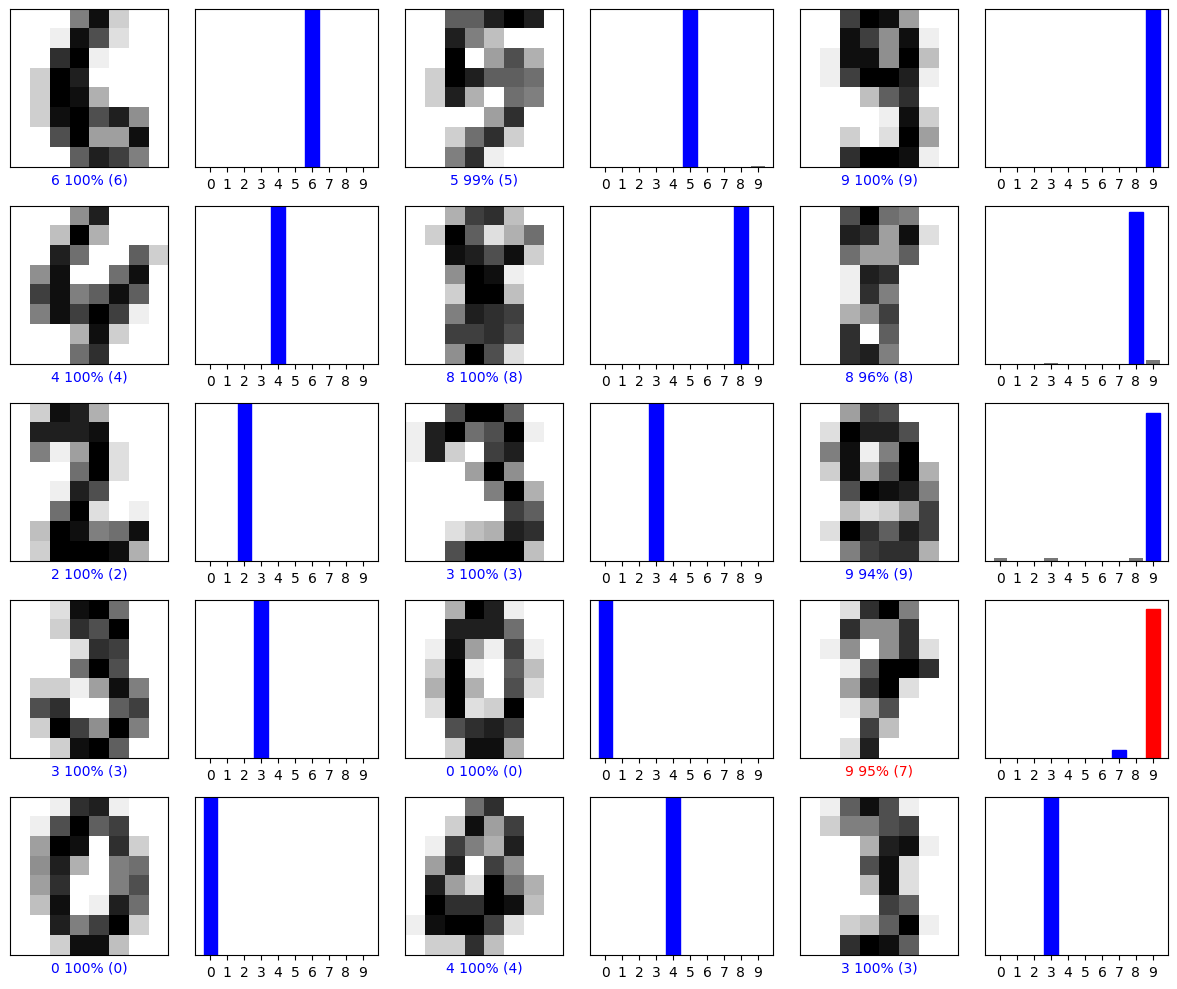

In [ ]:

num_rows = 5
num_cols = 3
num_images = num_rows * num_cols

plt.figure(figsize=(2 * 2 * num_cols, 2 * num_rows))

for i in range(num_images):
    plt.subplot(num_rows, 2 * num_cols, 2 * i + 1)
    plot_image(
        i,
        predictions,
        y_test,
        predicted_proba,
        X_test.reshape(len(X_test), 8, 8),
    )
    plt.subplot(num_rows, 2 * num_cols, 2 * i + 2)
    plot_value_array(
        i,
        predicted_proba,
        predictions,
        y_test,
    )
plt.tight_layout()
plt.show()


In [ ]:

# Se guardan el clasificador y sus métricas de prueba como evidencia verificable.

with open("../submission/estimator.pkl", "wb") as file:
    pickle.dump(estimator, file)

metrics = {
    "test_accuracy": accuracy_score(y_true=y_test, y_pred=predictions),
    "test_size": len(y_test),
}

with open("../submission/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
    
    
# ---


In [ ]:


# Se comprueba que el modelo almacenado conserva sus clases y probabilidades.

with open("../submission/estimator.pkl", "rb") as file:
    new_clf = pickle.load(file)

new_predictions = new_clf.predict(X_test)
new_predicted_proba = new_clf.predict_proba(X_test)

accuracy_score(y_true=y_test, y_pred=new_predictions), new_predicted_proba[0]


(0.9577308120133482,
 array([5.94501735e-07, 4.27915025e-06, 7.13086456e-09, 2.35089901e-13,
        2.04524906e-06, 3.46951527e-12, 9.99107615e-01, 9.62751591e-13,
        8.85459123e-04, 4.51487208e-18]))